# ML Lab 1
Data Exploration and Foundational Math

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (
    0.5 * study_hours
    + 0.3 * attendance
    + 0.2 * previous_mark
    + np.random.normal(0, 5, n)
)
df_raw = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score,
})
df_raw.loc[0:5, 'study_hours'] = np.nan   # Missing records
df_raw.loc[99, 'study_hours'] = 50      # Extreme outlier
df_raw.loc[98, 'attendance'] = -10      # Impossible negative attendance
display(df_raw.head())

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473


## Part A — Inspect and Clean

**1.** Student 99 has 50 study hours, which is much higher than the other values. I removed this row so it would not affect the results. Missing study hours and negative attendance were replaced using the median.

In [2]:
# Show the deliberately inserted outlier and count missing values
print('Outlier record:')
display(df_raw[df_raw['study_hours'] == 50])
print('Missing values before cleaning:')
print(df_raw.isna().sum())

df = df_raw[df_raw['study_hours'] != 50].copy()
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].median())
valid_attendance_median = df.loc[df['attendance'] >= 0, 'attendance'].median()
df.loc[df['attendance'] < 0, 'attendance'] = valid_attendance_median

print('After cleaning:', df.shape)
print('Missing values after cleaning:')
print(df.isna().sum())
print('Negative attendance values:', (df['attendance'] < 0).sum())

Outlier record:


,study_hours,attendance,previous_mark,final_score
99,50.0,73.570297,79.444433,46.41447


Missing values before cleaning:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64
After cleaning: (99, 4)
Missing values after cleaning:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64
Negative attendance values: 0


**2.** The inputs are `study_hours`, `attendance`, and `previous_mark`. The target is `final_score`. All four columns are numerical.

In [3]:
X = df[['study_hours', 'attendance', 'previous_mark']]
y = df['final_score']
print('Feature matrix shape:', X.shape)
print('All numerical columns:', df.select_dtypes(include='number').columns.tolist())
print('Target:', y.name)

Feature matrix shape: (99, 3)
All numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target: final_score


## Part B — Summarize

In [4]:
summary = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Standard deviation': df.std()
})
display(summary.round(3))

,Mean,Median,Standard deviation
study_hours,4.739,4.769,1.784
attendance,85.348,86.267,9.512
previous_mark,70.888,71.228,16.324
final_score,42.654,42.673,6.106


**Three observations:**

1. Students studied 4.74 hours on average, with a standard deviation of 1.78.
2. Average attendance is 85.35, with a standard deviation of 9.51.
3. The mean final score (42.65) is close to the median (42.67).

## Part C — Visualize

**1. Histogram of final scores**

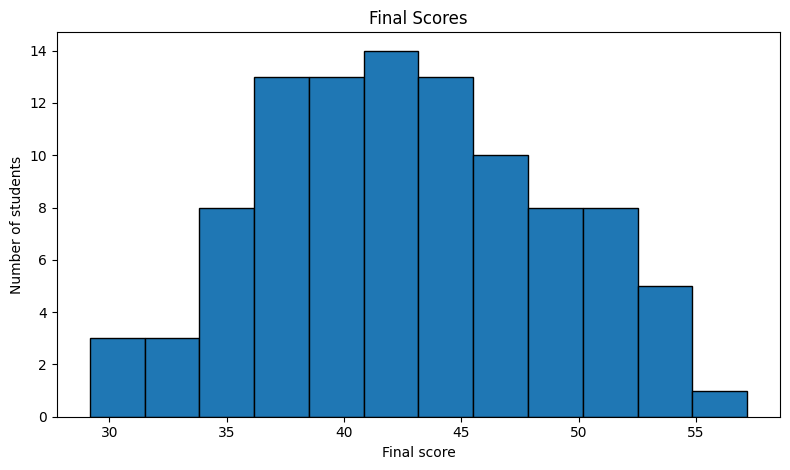

In [5]:
plt.figure(figsize=(8, 4.8))
plt.hist(df['final_score'], bins=12, edgecolor='black')
plt.xlabel('Final score')
plt.ylabel('Number of students')
plt.title('Final Scores')
plt.tight_layout()
plt.show()

**2. Study hours vs final score**

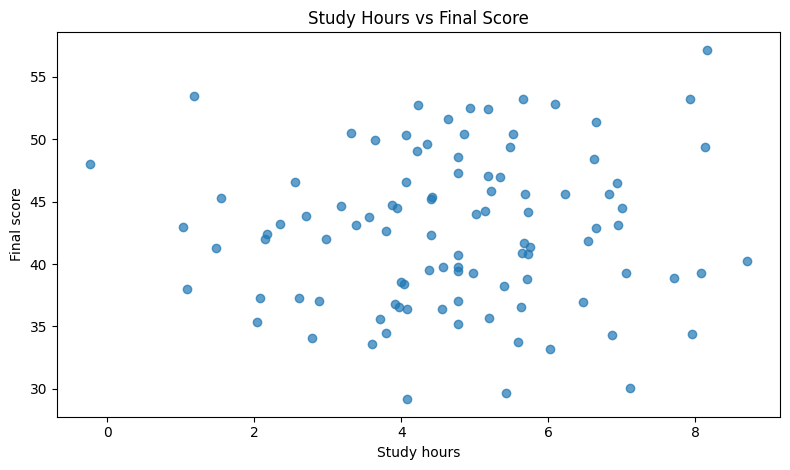

In [6]:
plt.figure(figsize=(8, 4.8))
plt.scatter(df['study_hours'], df['final_score'], alpha=0.7)
plt.xlabel('Study hours')
plt.ylabel('Final score')
plt.title('Study Hours vs Final Score')
plt.tight_layout()
plt.show()

The points are spread out, with no clear strong linear trend.

## Part D — Correlation and Causality

In [7]:
r = df['study_hours'].corr(df['final_score'], method='pearson')
print(f'Pearson correlation (study_hours, final_score): {r:.4f}')

Pearson correlation (study_hours, final_score): 0.0499


The correlation is about 0.05, showing a very weak positive linear relationship. Studying 10 hours does not guarantee a particular score. Previous academic preparation could affect both study time and results.

## Part E — Vectors and Dot Product

In [8]:
x = X.iloc[0].to_numpy(dtype=float)
w = np.array([0.5, 0.2, 0.4])
b = 5
y_hat = np.dot(w, x) + b
print('Features [study_hours, attendance, previous_mark]:', x.round(3))
print('Weights:', w)
print('Bias:', b)
print(f'Weighted result (w dot x + b): {y_hat:.4f}')


Features [study_hours, attendance, previous_mark]: [ 4.769 70.846 75.367]
Weights: [0.5 0.2 0.4]
Bias: 5
Weighted result (w dot x + b): 51.7003


The weights show how much each feature contributes to the calculation. The bias adds a constant value to the result.

## Part F — Scaling

In [9]:
scaled = df[['study_hours', 'previous_mark']].copy()
for col in scaled.columns:
    scaled[col] = (scaled[col] - scaled[col].mean()) / scaled[col].std(ddof=0)

print('Before scaling — value ranges:')
display(df[['study_hours', 'previous_mark']].agg(['min','max']).round(3))
print('First five standardized rows:')
display(scaled.head().round(3))
print('After scaling — means and population SDs:')
display(pd.DataFrame({'mean': scaled.mean(), 'std_ddof0': scaled.std(ddof=0)}).round(6))

Before scaling — value ranges:


,study_hours,previous_mark
min,-0.239,21.381
max,8.705,127.791


First five standardized rows:


,study_hours,previous_mark
0,0.017,0.276
1,0.017,0.463
2,0.017,0.946
3,0.017,0.919
4,0.017,-1.327


After scaling — means and population SDs:


,mean,std_ddof0
study_hours,-0.0,1.0
previous_mark,0.0,1.0


KNN uses distances. Without scaling, `previous_mark` has larger values than `study_hours` and may dominate the distance calculation. Standardization puts them on similar scales.